<a href="https://colab.research.google.com/github/MuhammadArisNaufal/AI_CHATBOT/blob/main/Copy_of_praktikum4Aris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
    )

In [3]:
file_path = '/content/drive/MyDrive/MachineLearningAriskun/praktikum4/Data/calonpembelimobil.csv'

df = pd.read_csv(file_path)
df.head()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB


In [5]:
df.isnull().sum()

,0
ID,0
Usia,0
Status,0
Kelamin,0
Memiliki_Mobil,0
Penghasilan,0
Beli_Mobil,0


In [7]:
df['Beli_Mobil'].unique()

array([1, 0])

In [9]:
df['Kelamin'].unique()

array([0, 1])

In [10]:
print('Distribusi Beli_Mobil:\n', df['Beli_Mobil'].value_counts())
print('\nDistribusi Jenis Kelamin:\n', df['Kelamin'].value_counts())

Distribusi Beli_Mobil:
 Beli_Mobil
1    633
0    367
Name: count, dtype: int64

Distribusi Jenis Kelamin:
 Kelamin
0    519
1    481
Name: count, dtype: int64


In [11]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
ID,1.000000,0.149779,-0.006634,0.014646,0.068555,0.254177,0.168614
Usia,0.149779,1.000000,0.051476,0.019454,0.090926,0.125859,0.100127
Status,-0.006634,0.051476,1.000000,-0.008561,0.048302,0.071714,0.048584
Kelamin,0.014646,0.019454,-0.008561,1.000000,0.035199,-0.054211,-0.147301
Memiliki_Mobil,0.068555,0.090926,0.048302,0.035199,1.000000,0.137823,0.102005
Penghasilan,0.254177,0.125859,0.071714,-0.054211,0.137823,1.000000,0.763930
Beli_Mobil,0.168614,0.100127,0.048584,-0.147301,0.102005,0.763930,1.000000


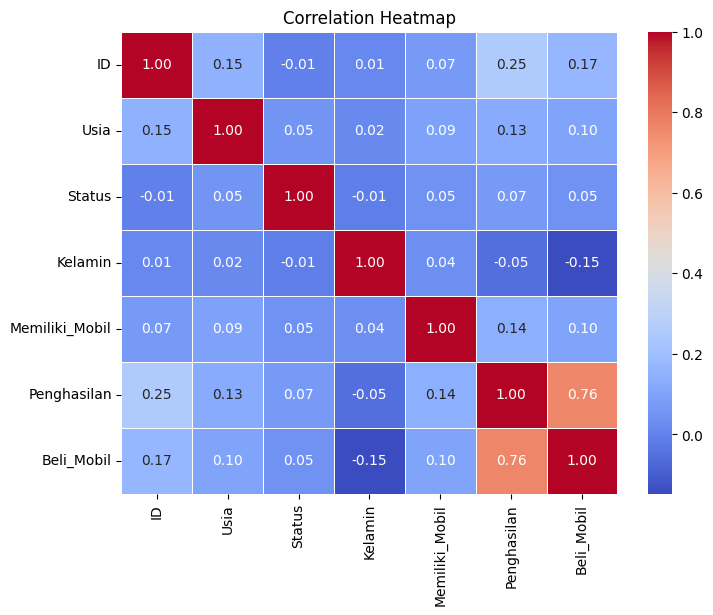

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [13]:
feature_num = ['Usia', 'Status', 'Penghasilan', 'Memiliki_Mobil']

use_cols = feature_num + ['Beli_Mobil']
df_model = df[use_cols].dropna().copy()

X = df_model[feature_num]
y = df_model['Beli_Mobil']

print('Shape of X:', X.shape)
print('Shape of y:', y.shape)

Shape of X: (1000, 4)
Shape of y: (1000,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42,
    stratify=y
    )
print('Data Latih:', X_train.shape)
print('Data Uji:', y_train.shape)

Data Latih: (800, 4)
Data Uji: (800,)


In [15]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_num)
        ],remainder='drop'
)

model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

clf.fit(X_train, y_train)
print('Model Regresi Logistik telah dilatih')

Model Regresi Logistik telah dilatih


In [16]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# Hitung metrik
print(f"Akurasi   : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

Akurasi   : 0.9100
Precision : 0.9739
Recall    : 0.8819
F1-Score  : 0.9256
ROC-AUC   : 0.9786


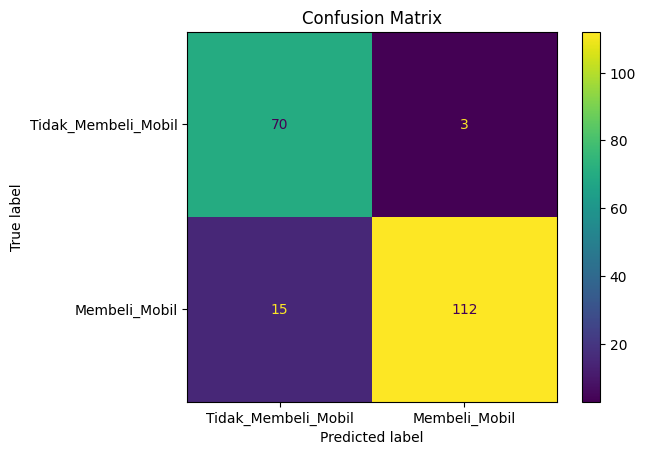

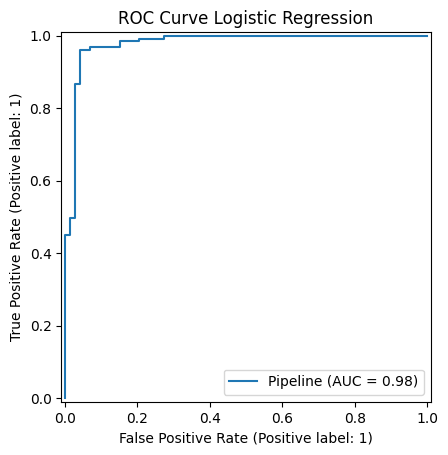

In [17]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['Tidak_Membeli_Mobil', 'Membeli_Mobil']
                       ).plot(values_format='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("ROC Curve Logistic Regression")
plt.show()

In [18]:
print(classification_report(y_test, y_pred, target_names=['Tidak_Membeli_Mobil (0)', 'Membeli_Mobil (1)']))

                         precision    recall  f1-score   support

Tidak_Membeli_Mobil (0)       0.82      0.96      0.89        73
      Membeli_Mobil (1)       0.97      0.88      0.93       127

               accuracy                           0.91       200
              macro avg       0.90      0.92      0.91       200
           weighted avg       0.92      0.91      0.91       200



In [20]:
scores = cross_val_score(clf, X, y, cv=5)

# Tampilkan hasil
print("Skor tiap fold:", scores)
print("Rata-rata akurasi:", np.mean(scores))
print("Standar deviasi:", np.std(scores))

Skor tiap fold: [0.77  0.905 0.96  0.965 0.955]
Rata-rata akurasi: 0.9109999999999999
Standar deviasi: 0.07371566997592843


In [21]:
feat_names = feature_num
coefs = clf.named_steps['model'].coef_[0]
odds = np.exp(coefs)

coef_df = pd.DataFrame({
    'Fitur': feat_names,
    'Koefisien (log-odds)': coefs,
    'Odds Ratio (e^coef)': odds
}).sort_values('Odds Ratio (e^coef)', ascending=False)

display(coef_df)

,Fitur,Koefisien (log-odds),Odds Ratio (e^coef)
2,Penghasilan,4.487226,88.874536
3,Memiliki_Mobil,0.057655,1.059350
0,Usia,-0.091467,0.912591
1,Status,-0.160953,0.851332


In [24]:
data_baru = pd.DataFrame({
    'Usia': [24, 60],
    'Status': [0, 2],
    'Kelamin': [0, 1],
    'Memiliki_Mobil': [0, 1],
    'Penghasilan': [10, 450]
})

pred = clf.predict(data_baru)
prob = clf.predict_proba(data_baru)[:, 1]

hasil = data_baru.copy()
hasil['Prob_BeliMobil'] = prob
hasil['Pred (0=Tidak,1=Ya)'] = pred

display(hasil)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_BeliMobil,"Pred (0=Tidak,1=Ya)"
0,24,0,0,0,10,0.000037,0
1,60,2,1,1,450,0.999962,1
